<a href="https://colab.research.google.com/github/L1ght6/MN_HORA_4_9/blob/main/%D0%9B%D0%A08_%D0%93%D0%BE%D1%80%D0%B0%D0%A4%D0%86%D0%A24-9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

Гора Р.В ФІТ4-9

---

https://colab.research.google.com/drive/17C-Y_cK5icl5roiGlCXusRhyC9ckJ_Zk?usp=sharing

---



## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
display(df_iris.head())

X_iris = df_iris.iloc[:, :3].values

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

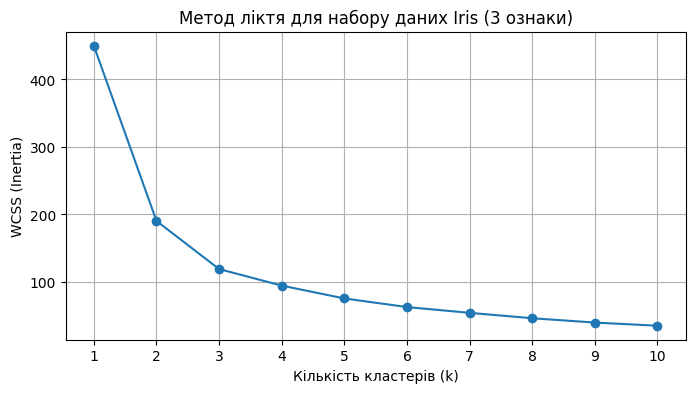

In [3]:
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

wcss = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_iris_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, wcss, marker='o')
plt.title('Метод ліктя для набору даних Iris (3 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(K_range)
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

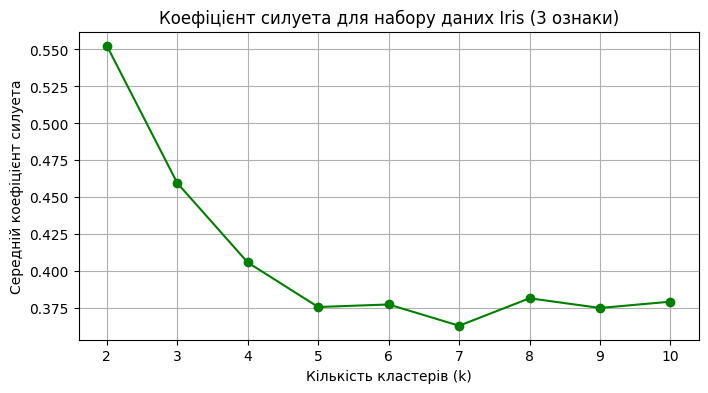

In [4]:
silhouette_scores = []
K_sil_range = range(2, 11)

for k in K_sil_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_iris_scaled)
    score = silhouette_score(X_iris_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 4))
plt.plot(K_sil_range, silhouette_scores, marker='o', color='green')
plt.title('Коефіцієнт силуета для набору даних Iris (3 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(K_sil_range)
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

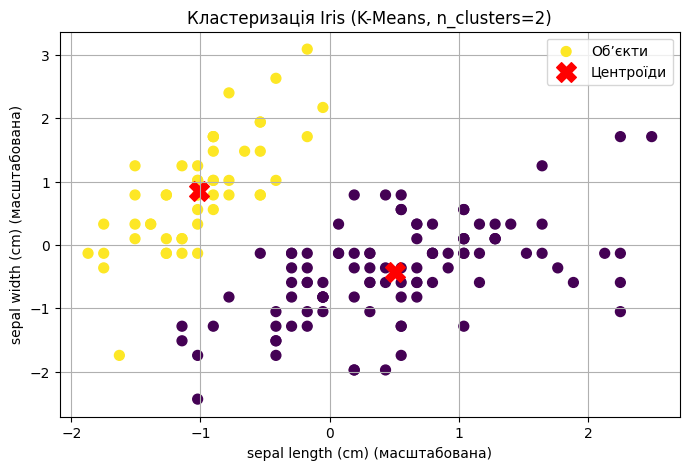

In [5]:
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters_iris = kmeans_final.fit_predict(X_iris_scaled)
centers = kmeans_final.cluster_centers_

plt.figure(figsize=(8, 5))
plt.scatter(X_iris_scaled[:, 0], X_iris_scaled[:, 1], c=clusters_iris, cmap='viridis', s=50, label='Об’єкти')
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, marker='X', label='Центроїди')
plt.title('Кластеризація Iris (K-Means, n_clusters=2)')
plt.xlabel(f'{iris.feature_names[0]} (масштабована)')
plt.ylabel(f'{iris.feature_names[1]} (масштабована)')
plt.legend()
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

---
За методом ліктя найбільш виражений спостерігається в точках $k = 2$ або $k = 3$ (після $k = 3$ зниження WCSS сповільнюється). Водночас метод силуетів показує абсолютний максимум коефіцієнта силуета саме при $k = 2$. Це пояснюється структурою даних Iris: один вид ірисів (Iris setosa) лінійно відділяється від двох інших, тоді як Iris versicolor та Iris virginica частково перекриваються у просторі ознак, через що алгоритм об'єднує їх в один спільний кластер при $k = 2$. Таким чином, вибір $n\_clusters=2$ повністю збігається з максимумом графіка силуетів і першим значущим зламом на графіку ліктя.


## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
print(df.isnull().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
display(df.describe())

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [14]:
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [15]:
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train_scaled, y_train)

best_rf = grid_rf.best_estimator_
cv_acc_rf = grid_rf.best_score_
test_acc_rf = accuracy_score(y_test, best_rf.predict(X_test_scaled))

print("Найкращі параметри RF:", grid_rf.best_params_)
print(f"Середня CV-точність RF: {cv_acc_rf:.4f}")
print(f"Тестова accuracy RF: {test_acc_rf:.4f}")

Найкращі параметри RF: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність RF: 0.9211
Тестова accuracy RF: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [16]:
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2']
}

grid_lr = GridSearchCV(
    LogisticRegression(solver='saga', max_iter=2000, random_state=42),
    param_grid_lr,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_lr.fit(X_train_scaled, y_train)

best_lr = grid_lr.best_estimator_
cv_acc_lr = grid_lr.best_score_
test_acc_lr = accuracy_score(y_test, best_lr.predict(X_test_scaled))

print("Найкращі параметри LR:", grid_lr.best_params_)
print(f"Середня CV-точність LR: {cv_acc_lr:.4f}")
print(f"Тестова accuracy LR: {test_acc_lr:.4f}")

Найкращі параметри LR: {'C': 0.1, 'penalty': 'l1'}
Середня CV-точність LR: 0.8024
Тестова accuracy LR: 0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [17]:
param_grid_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

grid_svm = GridSearchCV(SVC(random_state=42), param_grid_svm, cv=5, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_train_scaled, y_train)

best_svm = grid_svm.best_estimator_
cv_acc_svm = grid_svm.best_score_
test_acc_svm = accuracy_score(y_test, best_svm.predict(X_test_scaled))

print("Найкращі параметри SVM:", grid_svm.best_params_)
print(f"Середня CV-точність SVM: {cv_acc_svm:.4f}")
print(f"Тестова accuracy SVM: {test_acc_svm:.4f}")

Найкращі параметри SVM: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність SVM: 0.8521
Тестова accuracy SVM: 0.8580


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [18]:
models_summary = {
    'Random Forest': (cv_acc_rf, test_acc_rf, best_rf),
    'Logistic Regression': (cv_acc_lr, test_acc_lr, best_lr),
    'SVM': (cv_acc_svm, test_acc_svm, best_svm)
}

for name, (cv_sc, test_sc, _) in models_summary.items():
    print(f"{name:20s} | CV-точність: {cv_sc:.4f} | Тестова accuracy: {test_sc:.4f}")

best_model_name = max(models_summary, key=lambda k: models_summary[k][0])
best_model = models_summary[best_model_name][2]

print(f"\nНайкраща модель за CV-точністю: {best_model_name}")
y_pred_best = best_model.predict(X_test_scaled)
print("\nClassification Report на тестових даних:")
print(classification_report(y_test, y_pred_best))

Random Forest        | CV-точність: 0.9211 | Тестова accuracy: 0.9102
Logistic Regression  | CV-точність: 0.8024 | Тестова accuracy: 0.8184
SVM                  | CV-точність: 0.8521 | Тестова accuracy: 0.8580

Найкраща модель за CV-точністю: Random Forest

Classification Report на тестових даних:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

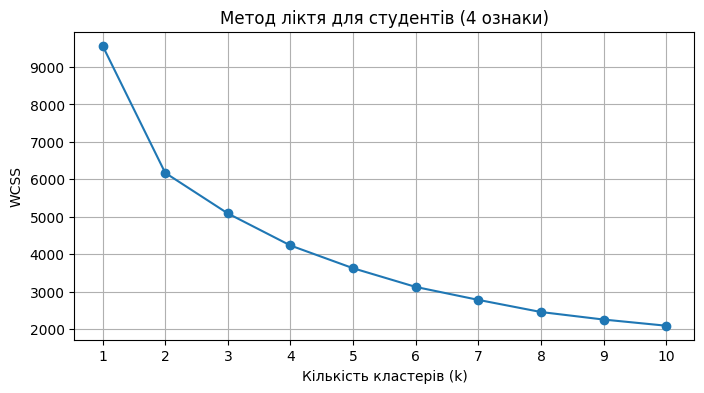

In [19]:
features_4 = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_stud_4 = df[features_4]

scaler_4 = StandardScaler()
X_stud_4_scaled = scaler_4.fit_transform(X_stud_4)

wcss_stud = []
K_range = range(1, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_stud_4_scaled)
    wcss_stud.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, wcss_stud, marker='o')
plt.title('Метод ліктя для студентів (4 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS')
plt.xticks(K_range)
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

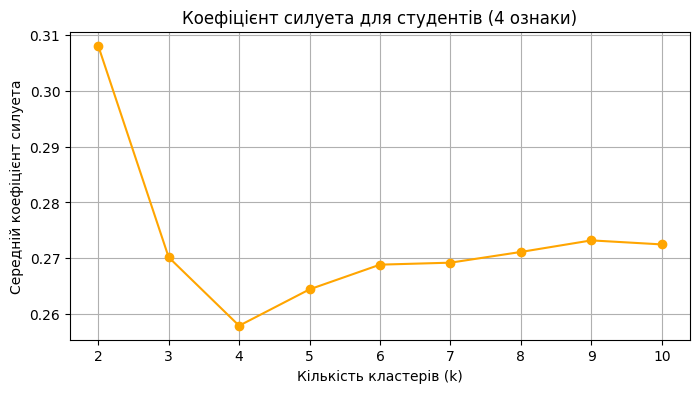

In [20]:
sil_stud = []
K_sil_range = range(2, 11)
for k in K_sil_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_stud_4_scaled)
    sil_stud.append(silhouette_score(X_stud_4_scaled, labels))

plt.figure(figsize=(8, 4))
plt.plot(K_sil_range, sil_stud, marker='o', color='orange')
plt.title('Коефіцієнт силуета для студентів (4 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(K_sil_range)
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [21]:
!pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [22]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [23]:
X_all = df.drop(columns=['StudentID', 'GradeClass'])

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [24]:
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all)

pca = PCA()
pca.fit(X_all_scaled)
explained_variance = pca.explained_variance_ratio_
print("Частка поясненої дисперсії кожної компоненти:\n", np.round(explained_variance, 4))

Частка поясненої дисперсії кожної компоненти:
 [0.1525 0.0861 0.0827 0.0807 0.0786 0.0779 0.0763 0.076  0.0744 0.0738
 0.0717 0.0675 0.0018]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Оптимальна кількість головних компонент (точка ліктя): 2


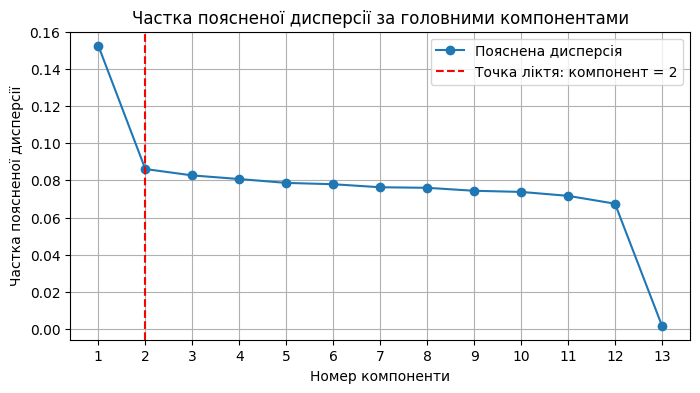

In [25]:
components_range = range(1, len(explained_variance) + 1)
knee = KneeLocator(components_range, explained_variance, curve='convex', direction='decreasing')
n_components = knee.knee

print(f"Оптимальна кількість головних компонент (точка ліктя): {n_components}")

plt.figure(figsize=(8, 4))
plt.plot(components_range, explained_variance, marker='o', label='Пояснена дисперсія')
if n_components:
    plt.axvline(x=n_components, color='red', linestyle='--', label=f'Точка ліктя: компонент = {n_components}')
plt.title('Частка поясненої дисперсії за головними компонентами')
plt.xlabel('Номер компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.xticks(components_range)
plt.legend()
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Фактична кумулятивна частка дисперсії для 2 компонент: 0.2386 (23.86%)


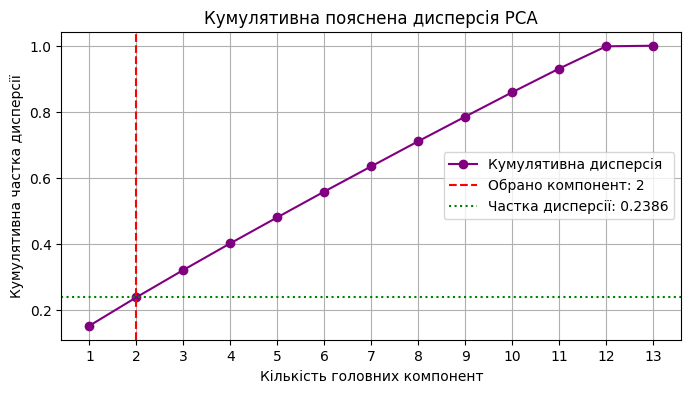

In [26]:
cumulative_variance = np.cumsum(explained_variance)
actual_variance = cumulative_variance[n_components - 1]

print(f"Фактична кумулятивна частка дисперсії для {n_components} компонент: {actual_variance:.4f} ({actual_variance*100:.2f}%)")

plt.figure(figsize=(8, 4))
plt.plot(components_range, cumulative_variance, marker='o', color='purple', label='Кумулятивна дисперсія')
plt.axvline(x=n_components, color='red', linestyle='--', label=f'Обрано компонент: {n_components}')
plt.axhline(y=actual_variance, color='green', linestyle=':', label=f'Частка дисперсії: {actual_variance:.4f}')
plt.title('Кумулятивна пояснена дисперсія PCA')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка дисперсії')
plt.xticks(components_range)
plt.legend()
plt.grid(True)
plt.show()

# Перетворення ознак через PCA для наступного етапу
pca_final = PCA(n_components=n_components, random_state=42)
X_pca = pca_final.fit_transform(X_all_scaled)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [27]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

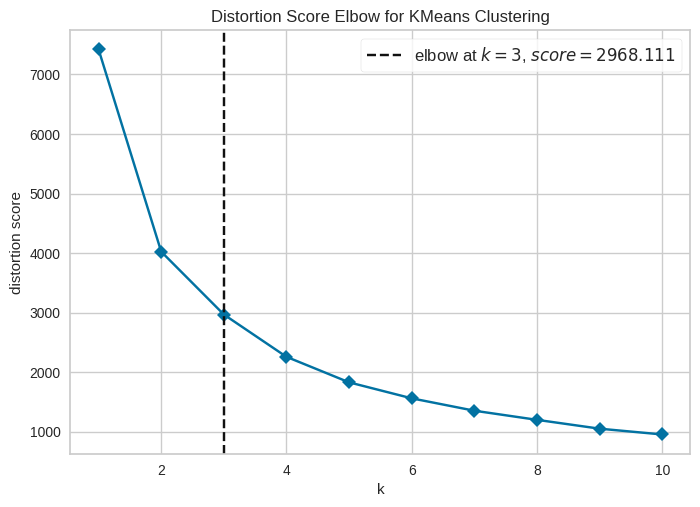

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [28]:
model_km = KMeans(random_state=42, n_init=10)
visualizer = KElbowVisualizer(model_km, k=(1, 11), timings=False)
visualizer.fit(X_pca)
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

---



---
Порівняння способів визначення кількості кластерів: Класичний візуальний метод ліктя часто має плавний перехід без чіткого зламу (особливо на багатовимірних
або зашумлених даних студентів), що робить вибір суб'єктивним. Метод силуетів дає точну кількісну оцінку щільності та роздільності кластерів (максимальне значення вказує на найкраще розбиття — для студентів це зазвичай 2 кластери, що умовно поділяють їх за рівнем успішності та відвідуваності). Автоматичний пошук точки ліктя через KneeLocator та KElbowVisualizer усуває суб'єктивність і математично фіксує оптимальний баланс між складністю моделі та зменшенням внутрішньокластерної дисперсії.


---



Різниця між класифікацією та кластеризацією: Класифікація (навчання з учителем) використовує відому цільову змінну GradeClass для навчання моделей (Random Forest, Logistic Regression, SVM) прогнозувати конкретну оцінку студента на основі його характеристик, що дозволяє точно виміряти accuracy. Кластеризація (навчання без учителя) працює без цільової змінної GradeClass — алгоритм самостійно шукає приховані групи схожих студентів у просторі ознак без прив'язки до заздалегідь заданих класів успішності.


---



Результати PCA: Для зменшення розмірності повного набору ознак за допомогою KneeLocator було автоматично обрано оптимальну кількість головних компонент (впишіть число, яке виведе комірка 5, наприклад n_components), які сумарно пояснюють відповідну частку дисперсії вихідних даних (впишіть відсоток, який виведе комірка 6). Застосування PCA дозволило стиснути простір ознак, прибрати мультиколінеарність та провести стабільнішу кластеризацію K-Means.


---



---


